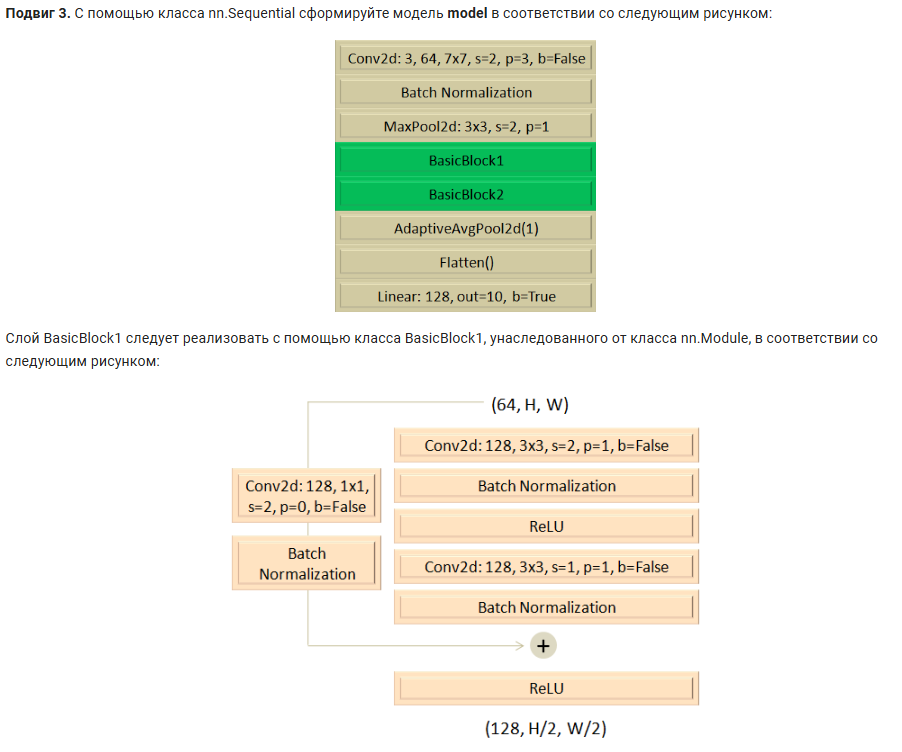

In [13]:
import torch
import torch.nn as nn

# здесь объявляйте классы BasicBlock1 и BasicBlock2


class BasicBlock1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128)
        )
        self.skip = nn.Sequential(
            nn.Conv2d(64, 128, 1, stride=2, padding=0, bias=False),
            nn.BatchNorm2d(128),
        )

    def forward(self, x):
        straight = self.net(x)
        skip = self.skip(x)
        return torch.relu(straight+skip)


class BasicBlock2(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(128, 128, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128)
        )

    def forward(self, x):
        return torch.relu(self.net(x) + x)

    
# здесь продолжайте программу
model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
    nn.BatchNorm2d(64),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
    BasicBlock1(),
    BasicBlock2(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128, 10, bias=True)
)


batch_size = 8
x = torch.rand(batch_size, 3, 32, 32) # тензор x в программе не менять
model.eval()
predict = model(x)

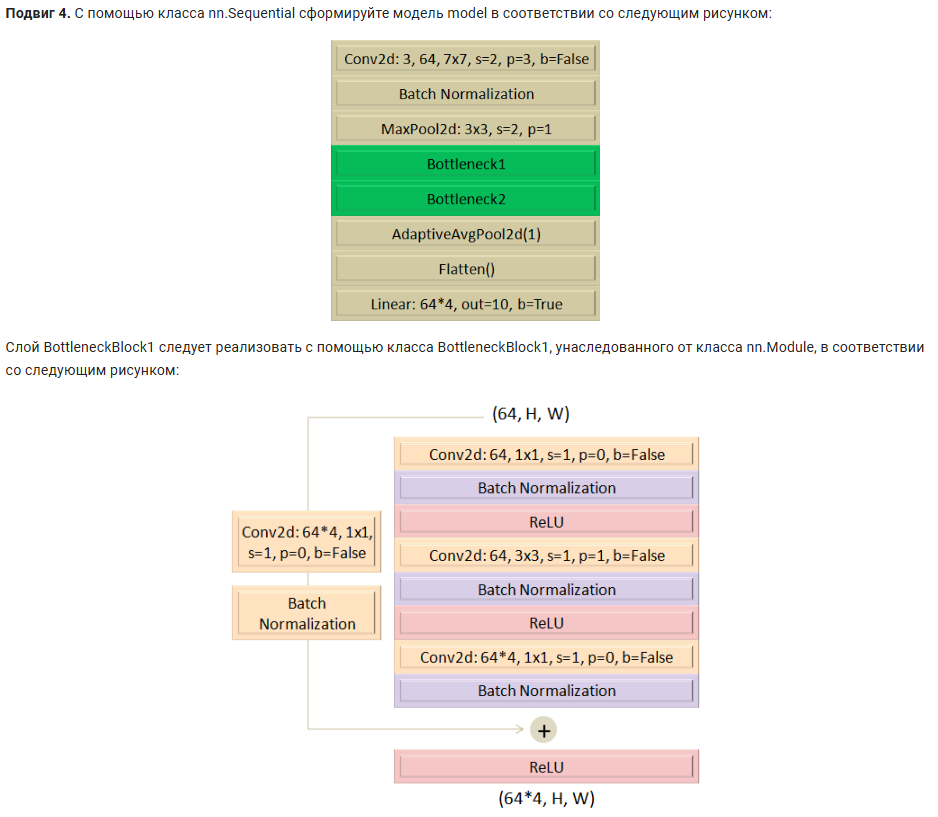

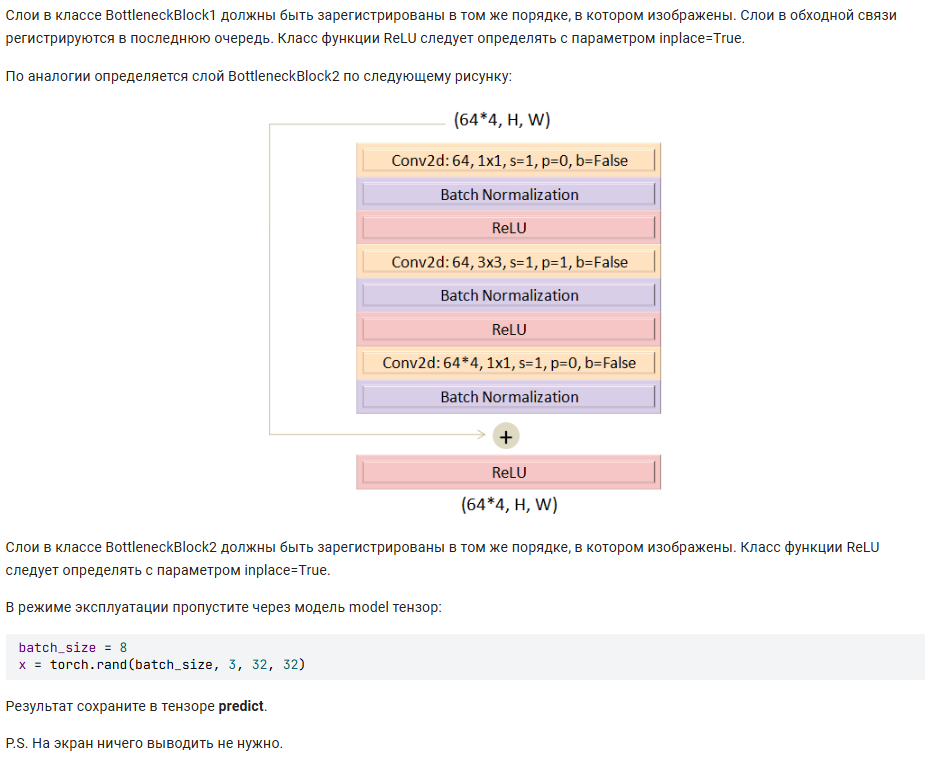


In [10]:
import torch
import torch.nn as nn

# здесь объявляйте классы BottleneckBlock1 и BottleneckBlock2
class BottleneckBlock1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(64, 64, 1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64*4, 1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(64*4)
        )
        self.skip = nn.Sequential(
            nn.Conv2d(64, 64*4, 1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(64*4),
        )

    def forward(self, x):
        straight = self.net(x)
        skip = self.skip(x)
        return torch.relu(straight+skip)

class BottleneckBlock2(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(64*4, 64, 1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64*4, 1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(64*4)
        )

    def forward(self, x):
        return torch.relu(self.net(x)+x)

model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
    nn.BatchNorm2d(64),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
    BottleneckBlock1(),
    BottleneckBlock2(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(64*4, 10, bias=True)
)



batch_size = 8
x = torch.rand(batch_size, 3, 32, 32) # тензор x в программе не менять

# здесь продолжайте программу
model.eval()
predict = model(x)
predict

torch.Size([8, 64, 8, 8])


tensor([[-0.1352,  0.0388,  0.0193,  0.1042, -0.0254, -0.0609, -0.0103,  0.0377,
          0.2156, -0.0412],
        [-0.1347,  0.0444,  0.0166,  0.1086, -0.0275, -0.0663, -0.0143,  0.0388,
          0.2005, -0.0347],
        [-0.1378,  0.0365,  0.0141,  0.1128, -0.0341, -0.0620, -0.0081,  0.0385,
          0.2103, -0.0340],
        [-0.1385,  0.0443,  0.0193,  0.1027, -0.0196, -0.0601, -0.0076,  0.0449,
          0.2098, -0.0325],
        [-0.1539,  0.0360,  0.0148,  0.1024, -0.0221, -0.0722, -0.0026,  0.0409,
          0.2116, -0.0355],
        [-0.1390,  0.0383,  0.0170,  0.1146, -0.0270, -0.0616, -0.0055,  0.0413,
          0.2057, -0.0349],
        [-0.1385,  0.0324,  0.0242,  0.1057, -0.0319, -0.0584, -0.0086,  0.0369,
          0.2187, -0.0350],
        [-0.1399,  0.0334,  0.0158,  0.1099, -0.0314, -0.0640, -0.0073,  0.0403,
          0.2123, -0.0442]], grad_fn=<AddmmBackward0>)